In [1]:
%pip install numpy scipy matplotlib pandas


Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [2]:
import numpy as np
import scipy
import matplotlib
import pandas as pd

print("NumPy:", np.__version__)
print("SciPy:", scipy.__version__)
print("Matplotlib:", matplotlib.__version__)
print("Pandas:", pd.__version__)
print("All libraries imported successfully.")


NumPy: 1.26.4
SciPy: 1.15.2
Matplotlib: 3.5.1
Pandas: 2.2.1
All libraries imported successfully.


In [3]:
from pathlib import Path

output_dir = Path("random_data")
output_dir.mkdir(exist_ok=True)

sample_size = 1024 * 1024

with open("/dev/urandom", "rb") as source:
    data = source.read(sample_size)

if len(data) != sample_size:
    raise IOError("Incorrect data size.")

(output_dir / "urandom.bin").write_bytes(data)

print("Random data generated successfully.")
print("File size:", len(data), "bytes")
print("File location:", (output_dir / "urandom.bin").resolve())


Random data generated successfully.
File size: 1048576 bytes
File location: /home/mnit/2024ucp1903/random_data/urandom.bin


In [5]:
import platform
from pathlib import Path

OUTPUT_DIR = Path("random_data")
OUTPUT_DIR.mkdir(exist_ok=True)

SAMPLE_SIZE = 1024 * 1024


In [6]:
if platform.system() != "Linux":
    raise OSError("This experiment requires Linux.")

with open("/dev/urandom", "rb") as source:
    data = source.read(SAMPLE_SIZE)

if len(data) != SAMPLE_SIZE:
    raise IOError("Incorrect number of bytes generated.")

(OUTPUT_DIR / "urandom.bin").write_bytes(data)

print("Generated:", len(data), "bytes")
print("File:", OUTPUT_DIR / "urandom.bin")


Generated: 1048576 bytes
File: random_data/urandom.bin


In [7]:
import subprocess
import shutil
import platform
from pathlib import Path

OUTPUT_DIR = Path("random_data")
OUTPUT_DIR.mkdir(exist_ok=True)

SAMPLE_SIZE = 1024 * 1024

openssl_path = shutil.which("openssl")

if openssl_path is None:
    raise FileNotFoundError("OpenSSL is not installed or not in PATH.")

version = subprocess.run(
    [openssl_path, "version"],
    capture_output=True,
    text=True,
    check=True
)

print("OpenSSL version:", version.stdout.strip())

openssl_file = OUTPUT_DIR / "openssl.bin"

subprocess.run(
    [
        openssl_path,
        "rand",
        "-out",
        str(openssl_file),
        str(SAMPLE_SIZE)
    ],
    check=True
)

openssl_data = openssl_file.read_bytes()

if len(openssl_data) != SAMPLE_SIZE:
    raise IOError("Incorrect number of bytes generated.")

print("Generated:", len(openssl_data), "bytes")
print("File:", openssl_file.resolve())


OpenSSL version: OpenSSL 3.0.2 15 Mar 2022 (Library: OpenSSL 3.0.2 15 Mar 2022)
Generated: 1048576 bytes
File: /home/mnit/2024ucp1903/random_data/openssl.bin


Linux /dev/urandom : 1048576 bytes
OpenSSL rand : 1048576 bytes


,Generator,Minimum Frequency,Maximum Frequency,Mean Frequency,Expected Frequency
0,Linux /dev/urandom,3890,4316,4096.0,4096.0
1,OpenSSL rand,3928,4287,4096.0,4096.0


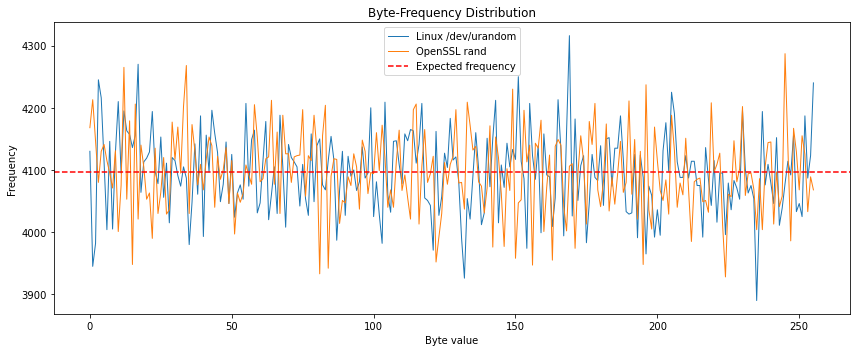

In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

OUTPUT_DIR = Path("random_data")

files = {
    "Linux /dev/urandom": OUTPUT_DIR / "urandom.bin",
    "OpenSSL rand": OUTPUT_DIR / "openssl.bin"
}

datasets = {}

for name, path in files.items():
    if not path.exists():
        raise FileNotFoundError(f"Missing dataset: {path}")

    data = np.frombuffer(path.read_bytes(), dtype=np.uint8)

    if len(data) < 1024 * 1024:
        raise ValueError(f"{name} contains less than 1 MiB.")

    datasets[name] = data

    print(name, ":", len(data), "bytes")

rows = []

for name, data in datasets.items():
    counts = np.bincount(data, minlength=256)

    rows.append({
        "Generator": name,
        "Minimum Frequency": int(counts.min()),
        "Maximum Frequency": int(counts.max()),
        "Mean Frequency": float(counts.mean()),
        "Expected Frequency": len(data) / 256
    })

display(pd.DataFrame(rows))

plt.figure(figsize=(12, 5))

for name, data in datasets.items():
    counts = np.bincount(data, minlength=256)
    plt.plot(counts, label=name, linewidth=1)

plt.axhline(1024 * 1024 / 256, color="red", linestyle="--",
            label="Expected frequency")

plt.xlabel("Byte value")
plt.ylabel("Frequency")
plt.title("Byte-Frequency Distribution")
plt.legend()
plt.tight_layout()
plt.show()


In [9]:
from scipy.stats import chisquare
import numpy as np
import pandas as pd

results = []

for name, data in datasets.items():
    observed = np.bincount(data, minlength=256)
    expected = np.full(256, len(data) / 256)

    chi_stat, p_value = chisquare(observed, f_exp=expected)

    results.append({
        "Generator": name,
        "Chi-Square Statistic": round(chi_stat, 4),
        "P-Value": round(p_value, 6),
        "Conclusion": (
            "Reject uniformity"
            if p_value < 0.05
            else "No significant evidence against uniformity"
        )
    })

results_df = pd.DataFrame(results)
display(results_df)


,Generator,Chi-Square Statistic,P-Value,Conclusion
0,Linux /dev/urandom,263.9409,0.336945,No significant evidence against uniformity
1,OpenSSL rand,265.2070,0.317212,No significant evidence against uniformity


In [10]:
bit_results = []

for name, data in datasets.items():
    bits = np.unpackbits(data)
    ones = int(bits.sum())
    zeros = len(bits) - ones

    bit_results.append({
        "Generator": name,
        "Zero Bits": zeros,
        "One Bits": ones,
        "Zero Percentage": round(zeros / len(bits) * 100, 4),
        "One Percentage": round(ones / len(bits) * 100, 4)
    })

bit_df = pd.DataFrame(bit_results)
display(bit_df)


,Generator,Zero Bits,One Bits,Zero Percentage,One Percentage
0,Linux /dev/urandom,4194334,4194274,50.0004,49.9996
1,OpenSSL rand,4196632,4191976,50.0278,49.9722


In [11]:
from scipy.stats import binomtest

monobit_results = []

for name, data in datasets.items():
    bits = np.unpackbits(data)
    ones = int(bits.sum())

    test = binomtest(
        ones,
        n=len(bits),
        p=0.5,
        alternative="two-sided"
    )

    monobit_results.append({
        "Generator": name,
        "One-Bit Proportion": round(ones / len(bits), 6),
        "P-Value": test.pvalue,
        "Conclusion": (
            "Reject unbiased-bit hypothesis"
            if test.pvalue < 0.05
            else "No significant evidence against unbiased bits"
        )
    })

display(pd.DataFrame(monobit_results))


,Generator,One-Bit Proportion,P-Value,Conclusion
0,Linux /dev/urandom,0.499996,0.983748,No significant evidence against unbiased bits
1,OpenSSL rand,0.499722,0.108007,No significant evidence against unbiased bits


In [12]:
correlation_results = []

for name, data in datasets.items():
    byte_values = data.astype(np.float64)

    byte_correlation = np.corrcoef(
        byte_values[:-1],
        byte_values[1:]
    )[0, 1]

    bits = np.unpackbits(data).astype(np.float64)

    bit_correlation = np.corrcoef(
        bits[:-1],
        bits[1:]
    )[0, 1]

    correlation_results.append({
        "Generator": name,
        "Byte Lag-1 Correlation": byte_correlation,
        "Bit Lag-1 Correlation": bit_correlation
    })

display(pd.DataFrame(correlation_results))



,Generator,Byte Lag-1 Correlation,Bit Lag-1 Correlation
0,Linux /dev/urandom,-0.000738,-0.000138
1,OpenSSL rand,0.001983,0.000142


In [13]:
import numpy as np
import pandas as pd

pattern_results = []

for name, data in datasets.items():
    byte_counts = np.bincount(data, minlength=256)

    repeated_bytes = int(np.maximum(byte_counts - 1, 0).sum())

    words = (
        data[:-1].astype(np.uint16) * 256
        + data[1:].astype(np.uint16)
    )

    word_counts = np.bincount(words, minlength=65536)

    repeated_words = int(np.maximum(word_counts - 1, 0).sum())

    pattern_results.append({
        "Generator": name,
        "Repeated Byte Occurrences": repeated_bytes,
        "Distinct Byte Values": int(np.count_nonzero(byte_counts)),
        "Distinct 16-Bit Words": int(np.count_nonzero(word_counts)),
        "Repeated 16-Bit Word Occurrences": repeated_words
    })

display(pd.DataFrame(pattern_results))


,Generator,Repeated Byte Occurrences,Distinct Byte Values,Distinct 16-Bit Words,Repeated 16-Bit Word Occurrences
0,Linux /dev/urandom,1048320,256,65536,983039
1,OpenSSL rand,1048320,256,65536,983039


In [14]:
from scipy.stats import norm

def runs_test(bits):
    bits = np.asarray(bits, dtype=np.uint8)

    n0 = int(np.count_nonzero(bits == 0))
    n1 = int(np.count_nonzero(bits == 1))
    n = n0 + n1

    if n0 == 0 or n1 == 0:
        return 1, np.nan, np.nan, 0.0

    runs = 1 + int(np.count_nonzero(bits[1:] != bits[:-1]))

    expected = 1 + (2 * n0 * n1) / n

    variance = (
        2 * n0 * n1 * (2 * n0 * n1 - n)
        / (n**2 * (n - 1))
    )

    z_score = (runs - expected) / np.sqrt(variance)
    p_value = 2 * norm.sf(abs(z_score))

    return runs, expected, z_score, p_value


runs_results = []

for name, data in datasets.items():
    bits = np.unpackbits(data)

    runs, expected, z_score, p_value = runs_test(bits)

    runs_results.append({
        "Generator": name,
        "Observed Runs": runs,
        "Expected Runs": round(expected, 2),
        "Z-Score": round(z_score, 4),
        "P-Value": p_value,
        "Conclusion": (
            "Reject runs-test null hypothesis"
            if p_value < 0.05
            else "Do not reject runs-test null hypothesis"
        )
    })

display(pd.DataFrame(runs_results))


,Generator,Observed Runs,Expected Runs,Z-Score,P-Value,Conclusion
0,Linux /dev/urandom,4194883,4194305.00,0.3991,0.689798,Do not reject runs-test null hypothesis
1,OpenSSL rand,4193709,4194303.71,-0.4107,0.681317,Do not reject runs-test null hypothesis


In [15]:
summary_results = []

for name, data in datasets.items():
    byte_counts = np.bincount(data, minlength=256)

    bit_data = np.unpackbits(data)
    one_bit_proportion = float(bit_data.mean())

    byte_correlation = float(np.corrcoef(
        data[:-1].astype(np.float64),
        data[1:].astype(np.float64)
    )[0, 1])

    bit_correlation = float(np.corrcoef(
        bit_data[:-1].astype(np.float64),
        bit_data[1:].astype(np.float64)
    )[0, 1])

    summary_results.append({
        "Generator": name,
        "Data Size (Bytes)": len(data),
        "Distinct Byte Values": int(np.count_nonzero(byte_counts)),
        "One-Bit Percentage": round(one_bit_proportion * 100, 4),
        "Byte Lag-1 Correlation": round(byte_correlation, 6),
        "Bit Lag-1 Correlation": round(bit_correlation, 6)
    })

summary_df = pd.DataFrame(summary_results)

display(summary_df)


,Generator,Data Size (Bytes),Distinct Byte Values,One-Bit Percentage,Byte Lag-1 Correlation,Bit Lag-1 Correlation
0,Linux /dev/urandom,1048576,256,49.9996,-0.000738,-0.000138
1,OpenSSL rand,1048576,256,49.9722,0.001983,0.000142


In [16]:
from pathlib import Path

OUTPUT_DIR = Path("random_data")
OUTPUT_DIR.mkdir(exist_ok=True)

summary_df.to_csv(
    OUTPUT_DIR / "statistical_summary.csv",
    index=False
)

print("Summary saved to:", (OUTPUT_DIR / "statistical_summary.csv").resolve())


Summary saved to: /home/mnit/2024ucp1903/random_data/statistical_summary.csv


In [17]:
from pathlib import Path

print("Current folder:", Path.cwd())
print("\nNotebook-related files:")

for path in Path.cwd().rglob("*.ipynb"):
    if ".ipynb_checkpoints" not in str(path):
        print(path.resolve())


Current folder: /home/mnit/2024ucp1903

Notebook-related files:
/home/mnit/2024ucp1903/Untitled.ipynb


In [18]:
from pathlib import Path

file_path = Path("random_data/urandom.bin")

print("File exists:", file_path.exists())
print

File exists: True


<function print>